In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

In [2]:
dataset = pd.read_csv("Heart_Disease_Prediction.csv")
dataset.head()

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,70.0,1,4,130,322.0,0,2,109,0,2.4,2,3,3,Presence
1,67.0,0,3,115,564.0,0,2,160,0,1.6,2,0,7,Absence
2,57.0,1,2,124,261.0,0,0,141,0,0.3,1,0,7,Presence
3,64.0,1,4,128,263.0,0,0,105,1,0.2,2,1,7,Absence
4,74.0,0,2,120,269.0,0,2,121,1,0.2,1,1,3,Absence


In [3]:
print(dataset.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      267 non-null    float64
 1   Sex                      270 non-null    int64  
 2   Chest pain type          270 non-null    int64  
 3   BP                       270 non-null    int64  
 4   Cholesterol              266 non-null    float64
 5   FBS over 120             270 non-null    int64  
 6   EKG results              270 non-null    int64  
 7   Max HR                   270 non-null    int64  
 8   Exercise angina          270 non-null    int64  
 9   ST depression            267 non-null    float64
 10  Slope of ST              270 non-null    int64  
 11  Number of vessels fluro  270 non-null    int64  
 12  Thallium                 270 non-null    int64  
 13  Heart Disease            270 non-null    object 
dtypes: float64(3), int64(10), 

In [4]:
dataset.shape

(270, 14)

In [5]:
dataset.isnull().sum()

Age                        3
Sex                        0
Chest pain type            0
BP                         0
Cholesterol                4
FBS over 120               0
EKG results                0
Max HR                     0
Exercise angina            0
ST depression              3
Slope of ST                0
Number of vessels fluro    0
Thallium                   0
Heart Disease              0
dtype: int64

In [6]:
dataset["Age"] = dataset["Age"].fillna(dataset["Age"].mean())
dataset["Cholesterol"] = dataset["Cholesterol"].fillna(dataset["Cholesterol"].mean())
dataset["ST depression"] = dataset["ST depression"].fillna(dataset["ST depression"].mean())

In [7]:
dataset.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
265    False
266    False
267    False
268    False
269    False
Length: 270, dtype: bool

In [8]:
dataset[dataset.duplicated()]

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
195,48.0,1,3,124,255.0,1,0,175,0,0.0,1,2,3,Absence


In [9]:
dataset.duplicated().sum()

np.int64(1)

In [10]:
dataset.drop_duplicates(inplace=True)

In [11]:
dataset[dataset.duplicated()]

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease


In [12]:
myencoder = LabelEncoder()
dataset["Heart Disease"] = myencoder.fit_transform(dataset["Heart Disease"])

In [13]:
dataset.head()

,Age,Sex,Chest pain type,BP,Cholesterol,FBS over 120,EKG results,Max HR,Exercise angina,ST depression,Slope of ST,Number of vessels fluro,Thallium,Heart Disease
0,70.0,1,4,130,322.0,0,2,109,0,2.4,2,3,3,1
1,67.0,0,3,115,564.0,0,2,160,0,1.6,2,0,7,0
2,57.0,1,2,124,261.0,0,0,141,0,0.3,1,0,7,1
3,64.0,1,4,128,263.0,0,0,105,1,0.2,2,1,7,0
4,74.0,0,2,120,269.0,0,2,121,1,0.2,1,1,3,0


In [35]:
inputFeatures = dataset.drop("Heart Disease", axis=1)
outputFeatures = dataset["Heart Disease"]
print(dataset.info())

<class 'pandas.core.frame.DataFrame'>
Index: 269 entries, 0 to 269
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      269 non-null    float64
 1   Sex                      269 non-null    int64  
 2   Chest pain type          269 non-null    int64  
 3   BP                       269 non-null    int64  
 4   Cholesterol              269 non-null    float64
 5   FBS over 120             269 non-null    int64  
 6   EKG results              269 non-null    int64  
 7   Max HR                   269 non-null    int64  
 8   Exercise angina          269 non-null    int64  
 9   ST depression            269 non-null    float64
 10  Slope of ST              269 non-null    int64  
 11  Number of vessels fluro  269 non-null    int64  
 12  Thallium                 269 non-null    int64  
 13  Heart Disease            269 non-null    int64  
dtypes: float64(3), int64(11)
memory

In [15]:
myScaler = StandardScaler()
inputFeatures = myScaler.fit_transform(inputFeatures)

In [16]:
print(dataset.info())

<class 'pandas.core.frame.DataFrame'>
Index: 269 entries, 0 to 269
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      269 non-null    float64
 1   Sex                      269 non-null    int64  
 2   Chest pain type          269 non-null    int64  
 3   BP                       269 non-null    int64  
 4   Cholesterol              269 non-null    float64
 5   FBS over 120             269 non-null    int64  
 6   EKG results              269 non-null    int64  
 7   Max HR                   269 non-null    int64  
 8   Exercise angina          269 non-null    int64  
 9   ST depression            269 non-null    float64
 10  Slope of ST              269 non-null    int64  
 11  Number of vessels fluro  269 non-null    int64  
 12  Thallium                 269 non-null    int64  
 13  Heart Disease            269 non-null    int64  
dtypes: float64(3), int64(11)
memory

In [17]:
inputFeatures = pd.DataFrame(inputFeatures, columns= ["Age", "Sex", "ChestPainType", "BP", "Cholesterol", "FBS over 120", "EKG results", "MaxHR", "Exercise angina", "ST depression", "Slope of ST", "Number of vessels fluro", "Thallium"]
)
print(inputFeatures.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 269 entries, 0 to 268
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      269 non-null    float64
 1   Sex                      269 non-null    float64
 2   ChestPainType            269 non-null    float64
 3   BP                       269 non-null    float64
 4   Cholesterol              269 non-null    float64
 5   FBS over 120             269 non-null    float64
 6   EKG results              269 non-null    float64
 7   MaxHR                    269 non-null    float64
 8   Exercise angina          269 non-null    float64
 9   ST depression            269 non-null    float64
 10  Slope of ST              269 non-null    float64
 11  Number of vessels fluro  269 non-null    float64
 12  Thallium                 269 non-null    float64
dtypes: float64(13)
memory usage: 27.4 KB
None


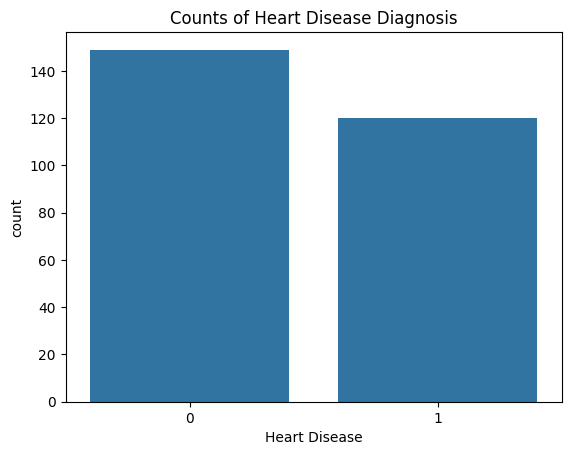

In [27]:
sns.countplot(x="Heart Disease", data=dataset)
plt.title("Counts of Heart Disease Diagnosis")
plt.show()

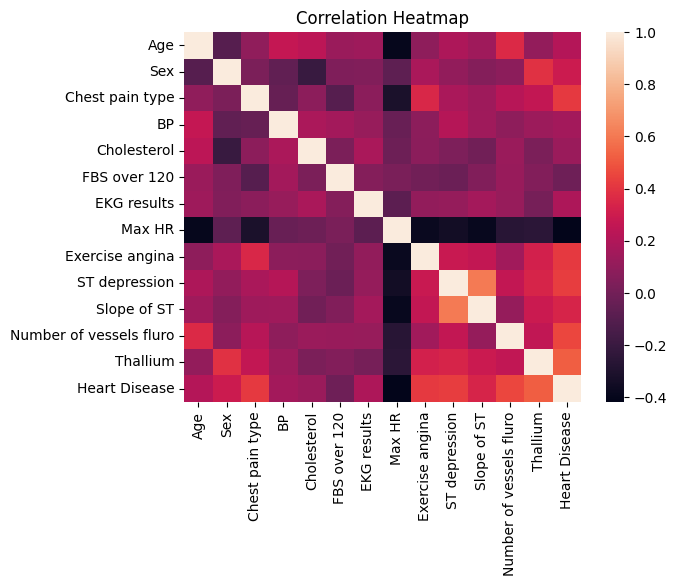

In [53]:
sns.heatmap(dataset.corr(numeric_only=True))
plt.title("Correlation Heatmap")
plt.show()

In [59]:
x_train, x_test, y_train, y_test = train_test_split(inputFeatures, outputFeatures, test_size=0.3, random_state=0)
supportVectorModel = SVC()
trained = supportVectorModel.fit(x_train, y_train)
results = trained.predict(x_test)
report = classification_report(y_test, results)
confusionMatrix = confusion_matrix(y_test, results)
print("Confusion Matrix:\n", confusionMatrix)
print("\n\nClassification Report:\n", report)

Confusion Matrix:
 [[47  1]
 [11 22]]


Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.98      0.89        48
           1       0.96      0.67      0.79        33

    accuracy                           0.85        81
   macro avg       0.88      0.82      0.84        81
weighted avg       0.87      0.85      0.85        81



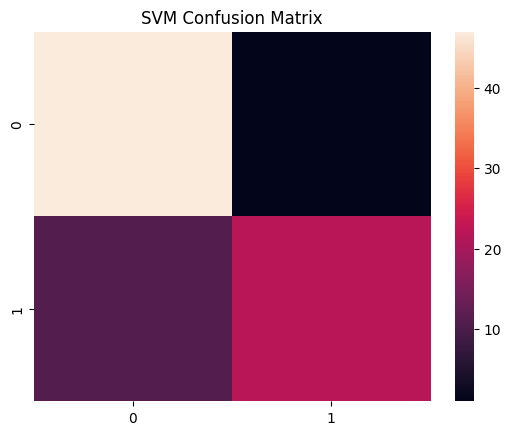

In [60]:
sns.heatmap(confusionMatrix)
plt.title("SVM Confusion Matrix")
plt.show()

In [61]:
outfile = open("svm_model.pkl", 'wb')
pickle.dump(trained, outfile)
outfile.close()

In [65]:
randomForestModel = RandomForestClassifier(n_estimators = 100)
trained = randomForestModel.fit(x_train, y_train)
results = trained.predict(x_test)
report = classification_report(y_test, results)
confusionMatrix = confusion_matrix(y_test, results)
print("Confusion Matrix:\n", confusionMatrix)
print("\n\nClassification Report:\n", report)

Confusion Matrix:
 [[46  2]
 [ 8 25]]


Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.96      0.90        48
           1       0.93      0.76      0.83        33

    accuracy                           0.88        81
   macro avg       0.89      0.86      0.87        81
weighted avg       0.88      0.88      0.87        81



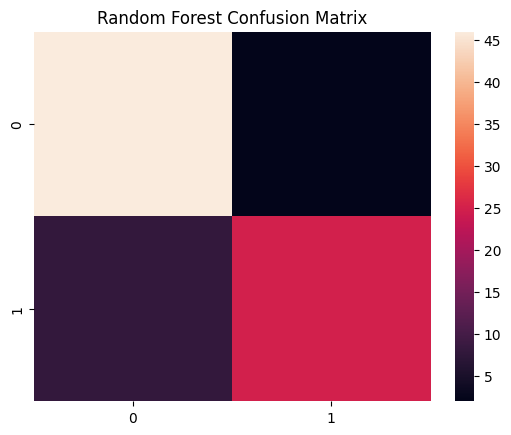

In [66]:
sns.heatmap(confusionMatrix)
plt.title("Random Forest Confusion Matrix")
plt.show()

In [67]:
outfile = open("random_forest_model.pkl", 'wb')
pickle.dump(trained, outfile)
outfile.close()